In [3]:
import json

json_path = "CelebA_Spoof_/CelebA_Spoof/metas/intra_test/train_label.json"

with open(json_path, "r") as f:
    data = json.load(f)

print(type(data))
print(len(data))

<class 'dict'>
494405


In [4]:
first_key = list(data.keys())[0]

print(first_key)
print(data[first_key])

Data/train/2623/live/000000.jpg
[0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0]


In [5]:
import os

meta_path = "CelebA_Spoof_/CelebA_Spoof/metas"

for root, dirs, files in os.walk(meta_path):
    print("\nFolder:", root)
    for f in files:
        print("   ", f)


Folder: CelebA_Spoof_/CelebA_Spoof/metas

Folder: CelebA_Spoof_/CelebA_Spoof/metas/protocol2
    data_description

Folder: CelebA_Spoof_/CelebA_Spoof/metas/protocol2/test_on_middle_quality_device
    train_label.json
    test_label.json

Folder: CelebA_Spoof_/CelebA_Spoof/metas/protocol2/test_on_high_quality_device
    train_label.json
    test_label.json

Folder: CelebA_Spoof_/CelebA_Spoof/metas/protocol2/test_on_low_quality_device
    train_label.json
    test_label.json

Folder: CelebA_Spoof_/CelebA_Spoof/metas/intra_test
    train_label.json
    test_label.json
    train_label.txt
    test_label.txt

Folder: CelebA_Spoof_/CelebA_Spoof/metas/protocol1
    train_label.json
    test_label.json
    data_description


In [6]:
import os

dataset_root = "CelebA_Spoof_/CelebA_Spoof"

bb_file = None

for root, dirs, files in os.walk(dataset_root):
    for file in files:
        if file.endswith("_BB.txt"):
            bb_file = os.path.join(root, file)
            break
    if bb_file:
        break

print("Bounding Box File:")
print(bb_file)

Bounding Box File:
CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/014427_BB.txt


In [7]:
with open(bb_file, "r") as f:
    content = f.read()

print(content)

40 47 120 148 0.99988365



In [8]:
values = content.strip().split()

print("Number of Values :", len(values))

for i, v in enumerate(values):
    print(f"Value {i+1} :", v)

Number of Values : 5
Value 1 : 40
Value 2 : 47
Value 3 : 120
Value 4 : 148
Value 5 : 0.99988365


In [9]:
image_file = bb_file.replace("_BB.txt", ".jpg")

print(image_file)
print(os.path.exists(image_file))

CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/014427.jpg
True


Image Size : (334, 375)


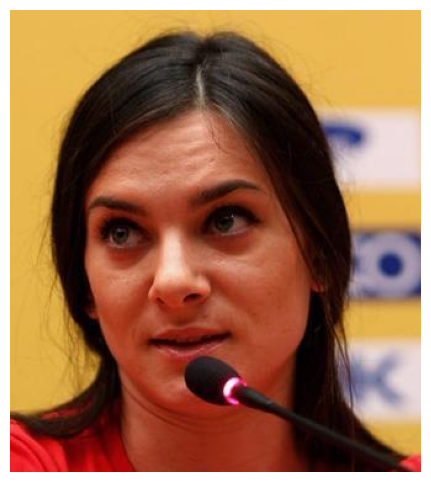

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(image_file)

print("Image Size :", img.size)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [15]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open(image_file)

print("Image Width :", img.width)
print("Image Height:", img.height)

with open(bb_file, "r") as f:
    vals = list(map(float, f.read().split()))

print("\nBB Values:", vals)

print("\nValue 1 / Width  =", vals[0] / img.width)
print("Value 2 / Height =", vals[1] / img.height)
print("Value 3 / Width  =", vals[2] / img.width)
print("Value 4 / Height =", vals[3] / img.height)

Image Width : 334
Image Height: 375

BB Values: [40.0, 47.0, 120.0, 148.0, 0.99988365]

Value 1 / Width  = 0.11976047904191617
Value 2 / Height = 0.12533333333333332
Value 3 / Width  = 0.3592814371257485
Value 4 / Height = 0.39466666666666667


In [16]:
import os

count = 0

for root, dirs, files in os.walk("CelebA_Spoof_/CelebA_Spoof"):
    for file in files:
        if file.endswith("_BB.txt"):
            path = os.path.join(root, file)

            with open(path) as f:
                print(file, ":", f.read().strip())

            count += 1

            if count == 10:
                break
    if count == 10:
        break

014427_BB.txt : 40 47 120 148 0.99988365
474873_BB.txt : 61 51 80 114 0.9979798
286553_BB.txt : 54 54 127 165 0.99993706
312460_BB.txt : 68 38 91 123 0.9983352
252807_BB.txt : 38 57 101 139 0.9998118
455458_BB.txt : 55 53 87 116 0.99723476
168376_BB.txt : 52 60 113 160 0.9999219
107187_BB.txt : 65 41 103 143 0.9998252
222729_BB.txt : 33 35 128 159 0.9999832
102303_BB.txt : 91 75 57 92 0.9991702


In [15]:
pip install mediapipe

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.5/36.5 MB 4.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 8.2 MB/s eta 0:00:0000:0100:01m

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [17]:
import os
import cv2
import shutil
import numpy as np
import pandas as pd
import mediapipe as mp
import matplotlib.pyplot as plt

from tqdm import tqdm

In [4]:
%pip install tqdm


[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [18]:
from tqdm import tqdm
print("tqdm installed successfully!")

tqdm installed successfully!


In [19]:
# Original dataset

DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

TRAIN_DIR = os.path.join(DATASET_ROOT, "Data", "train")
TEST_DIR = os.path.join(DATASET_ROOT, "Data", "test")

# Output folder

OUTPUT_ROOT = "CelebA_Spoof_Cropped"

TRAIN_OUTPUT = os.path.join(OUTPUT_ROOT, "train")
TEST_OUTPUT = os.path.join(OUTPUT_ROOT, "test")

os.makedirs(TRAIN_OUTPUT, exist_ok=True)
os.makedirs(TEST_OUTPUT, exist_ok=True)

print("Dataset Root :", DATASET_ROOT)
print("Output Folder:", OUTPUT_ROOT)

Dataset Root : CelebA_Spoof_/CelebA_Spoof
Output Folder: CelebA_Spoof_Cropped


In [20]:
mp_face_detection = mp.solutions.face_detection

face_detector = mp_face_detection.FaceDetection(
    model_selection=1,
    min_detection_confidence=0.5
)

print("MediaPipe Face Detector Initialized Successfully!")

MediaPipe Face Detector Initialized Successfully!


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1785423806.134010 2534616 inference_feedback_manager.cc:114] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


In [21]:
import mediapipe as mp

print(mp.__version__)
print(mp)

0.10.14
<module 'mediapipe' from '/home/jupyter-varshinis.23cse/myenv/lib/python3.12/site-packages/mediapipe/__init__.py'>


In [22]:
import mediapipe as mp

print(mp.__file__)

/home/jupyter-varshinis.23cse/myenv/lib/python3.12/site-packages/mediapipe/__init__.py


In [10]:
%pip uninstall mediapipe -y
%pip install mediapipe==0.10.14

Found existing installation: mediapipe 1.0.0
Uninstalling mediapipe-1.0.0:
  Successfully uninstalled mediapipe-1.0.0
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 5.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.3/87.3 MB 7.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 9.7 MB/s eta 0:00:00ta 0:00:01

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import mediapipe as mp

print(mp.__version__)

mp_face_detection = mp.solutions.face_detection
print("Success")

0.10.14
Success


In [3]:
%pip install ultralytics
%pip install onnxruntime
%pip install tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.8/846.8 kB 25.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.3/57.3 MB 4.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 807.9/807.9 kB 12.7 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.2/19.2 MB 6.2 MB/s eta 0:00:0000:0100:01

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 24.2 -> 26.1.2
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [23]:
import cv2

print(cv2.__version__)

5.0.0


CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/148326.jpg


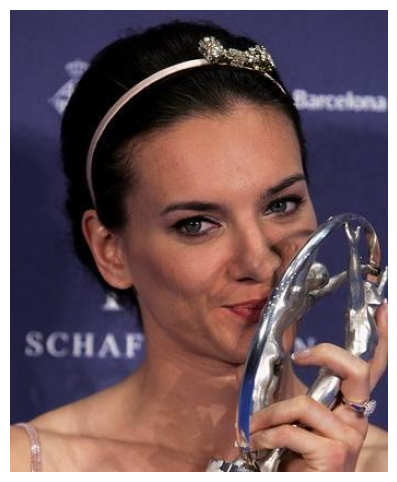

In [24]:
import cv2
import matplotlib.pyplot as plt
import os

sample_image = None

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.endswith(".jpg"):
            sample_image = os.path.join(root, file)
            break
    if sample_image:
        break

print(sample_image)

img = cv2.imread(sample_image)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [25]:
import os

# Original dataset
DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

TRAIN_DIR = os.path.join(DATASET_ROOT, "Data", "train")
TEST_DIR = os.path.join(DATASET_ROOT, "Data", "test")

# Output folder
OUTPUT_ROOT = "CelebA_Spoof_Cropped"

TRAIN_OUTPUT = os.path.join(OUTPUT_ROOT, "train")
TEST_OUTPUT = os.path.join(OUTPUT_ROOT, "test")

os.makedirs(TRAIN_OUTPUT, exist_ok=True)
os.makedirs(TEST_OUTPUT, exist_ok=True)

print("TRAIN_DIR :", TRAIN_DIR)
print("TEST_DIR  :", TEST_DIR)

TRAIN_DIR : CelebA_Spoof_/CelebA_Spoof/Data/train
TEST_DIR  : CelebA_Spoof_/CelebA_Spoof/Data/test


Sample Image: CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/148326.jpg


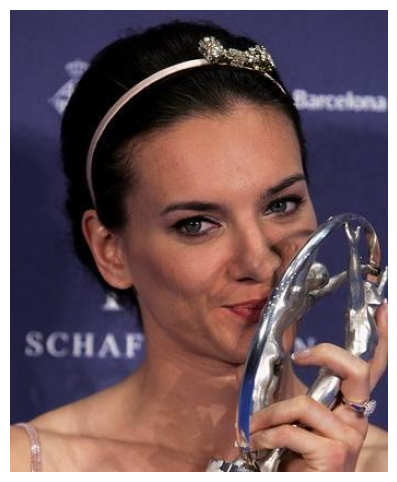

In [26]:
import cv2
import matplotlib.pyplot as plt

sample_image = None

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith(".jpg"):
            sample_image = os.path.join(root, file)
            break
    if sample_image:
        break

print("Sample Image:", sample_image)

img = cv2.imread(sample_image)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [27]:
import os

# Dataset Paths
DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

TRAIN_DIR = os.path.join(DATASET_ROOT, "Data", "train")
TEST_DIR = os.path.join(DATASET_ROOT, "Data", "test")

print("TRAIN_DIR:", TRAIN_DIR)
print("Exists:", os.path.exists(TRAIN_DIR))

TRAIN_DIR: CelebA_Spoof_/CelebA_Spoof/Data/train
Exists: True


In [28]:
bb_file = sample_image.replace(".jpg", "_BB.txt")

print("Bounding Box File:")
print(bb_file)

with open(bb_file, "r") as f:
    values = list(map(float, f.read().split()))

print(values)

Bounding Box File:
CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/148326_BB.txt
[73.0, 47.0, 109.0, 122.0, 0.99925774]


In [30]:
import os

MODEL_PATH = "saved_models/yolov5s-face.onnx"

print("Model Exists:", os.path.exists(MODEL_PATH))
print("Model Path :", MODEL_PATH)

Model Exists: False
Model Path : saved_models/yolov5s-face.onnx


In [31]:
import cv2

MODEL_PATH = "saved_models/face_detection_yunet_2023mar.onnx"

face_detector = cv2.FaceDetectorYN.create(
    model=MODEL_PATH,
    config="",
    input_size=(320, 320),
    score_threshold=0.8,
    nms_threshold=0.3,
    top_k=5000
)

print("YuNet Face Detector Loaded Successfully!")

YuNet Face Detector Loaded Successfully!


[ WARN:0@105.534] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


CelebA_Spoof_/CelebA_Spoof/Data/train/10039/live/148326.jpg


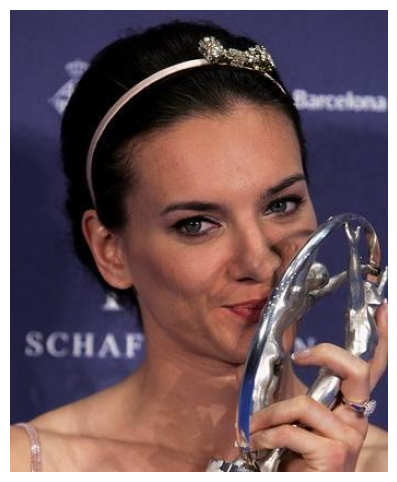

In [32]:
import cv2
import os
import matplotlib.pyplot as plt

sample_image = None

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith(".jpg"):
            sample_image = os.path.join(root, file)
            break
    if sample_image:
        break

print(sample_image)

image = cv2.imread(sample_image)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

In [33]:
h, w = image.shape[:2]

face_detector.setInputSize((w, h))

_, faces = face_detector.detect(image)

print(faces)

[[108.43884     90.21616    160.3982     228.26515    177.32121
  198.78981    242.06323    185.80554    236.56543    237.73962
  194.51755    274.88577    245.45567    264.26227      0.93302685]]


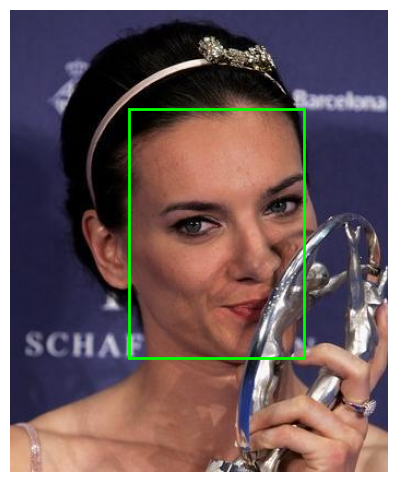

In [34]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Get first detected face
x, y, w, h = faces[0][:4]

fig, ax = plt.subplots(figsize=(6,6))
ax.imshow(image_rgb)

rect = patches.Rectangle(
    (x, y),
    w,
    h,
    linewidth=2,
    edgecolor="lime",
    facecolor="none"
)

ax.add_patch(rect)

plt.axis("off")
plt.show()

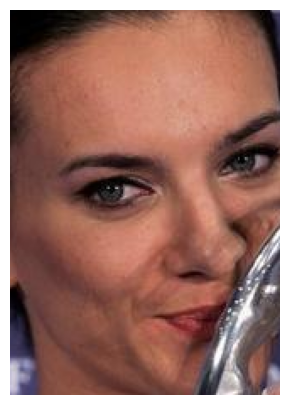

Face Shape: (228, 160, 3)


In [35]:
x, y, w, h = faces[0][:4]

# Convert to integers
x = int(x)
y = int(y)
w = int(w)
h = int(h)

# Crop
face = image[y:y+h, x:x+w]

plt.figure(figsize=(5,5))
plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("Face Shape:", face.shape)

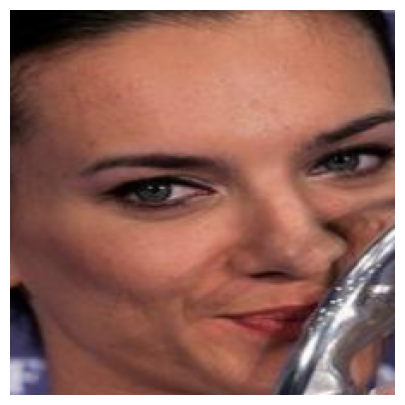

Resized Shape: (224, 224, 3)


In [36]:
face_resized = cv2.resize(face, (224,224))

plt.figure(figsize=(5,5))
plt.imshow(cv2.cvtColor(face_resized, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

print("Resized Shape:", face_resized.shape)

In [37]:
import cv2
import os

def crop_face(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]

    detector.setInputSize((w, h))

    _, faces = detector.detect(image)

    if faces is None:
        return None

    # Take the highest-confidence detection
    x, y, bw, bh = faces[0][:4]

    x = int(x)
    y = int(y)
    bw = int(bw)
    bh = int(bh)

    face = image[y:y+bh, x:x+bw]

    face = cv2.resize(face, (224,224))

    return face

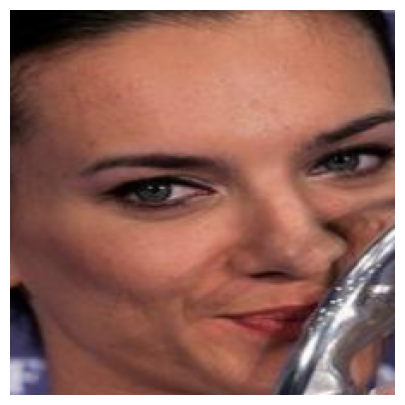

In [19]:
face = crop_face(sample_image, face_detector)

if face is None:
    print("Face Not Found")
else:
    plt.figure(figsize=(5,5))
    plt.imshow(cv2.cvtColor(face, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

In [20]:
save_path = "test_face.jpg"

cv2.imwrite(save_path, face)

print("Saved Successfully:", save_path)

Saved Successfully: test_face.jpg


In [21]:
from pathlib import Path

def process_image(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]
    detector.setInputSize((w, h))

    _, faces = detector.detect(image)

    if faces is None:
        return None

    # Highest confidence face
    x, y, bw, bh = faces[0][:4]

    x = max(0, int(x))
    y = max(0, int(y))
    bw = int(bw)
    bh = int(bh)

    face = image[y:y+bh, x:x+bw]

    if face.size == 0:
        return None

    face = cv2.resize(face, (224,224))

    return face

In [22]:
from tqdm import tqdm

count = 0

for root, dirs, files in os.walk(TRAIN_DIR):

    for file in files:

        if not file.lower().endswith(".jpg"):
            continue

        image_path = os.path.join(root, file)

        face = process_image(image_path, face_detector)

        if face is None:
            continue

        # Preserve folder structure
        relative_path = os.path.relpath(image_path, TRAIN_DIR)

        save_path = os.path.join(TRAIN_OUTPUT, relative_path)

        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        cv2.imwrite(save_path, face)

        count += 1

        if count == 100:
            break

    if count == 100:
        break

print("Saved", count, "cropped images.")

Saved 100 cropped images.


In [39]:
import cv2

def process_image(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]
    detector.setInputSize((w, h))

    _, faces = detector.detect(image)

    if faces is None:
        return None

    x, y, bw, bh = faces[0][:4]

    x = max(0, int(x))
    y = max(0, int(y))
    bw = int(bw)
    bh = int(bh)

    face = image[y:y+bh, x:x+bw]

    if face.size == 0:
        return None

    face = cv2.resize(face, (224,224))

    return face

In [ ]:
from tqdm import tqdm
import os
import cv2

saved = 0
failed = 0
skipped = 0

for root, dirs, files in os.walk(TRAIN_DIR):

    for file in tqdm(files, leave=False):

        if not file.lower().endswith(".jpg"):
            continue

        image_path = os.path.join(root, file)

        relative_path = os.path.relpath(image_path, TRAIN_DIR)
        save_path = os.path.join(TRAIN_OUTPUT, relative_path)

        # Skip if already cropped
        if os.path.exists(save_path):
            skipped += 1
            continue

        face = process_image(image_path, face_detector)

        if face is None:
            failed += 1
            continue

        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        cv2.imwrite(save_path, face)

        saved += 1

print("="*50)
print("Cropping Completed")
print("="*50)
print("Newly Saved :", saved)
print("Skipped     :", skipped)
print("Failed      :", failed)

  0%|          | 0/4 [00:00<?, ?it/s]              

In [1]:
import cv2

def process_image(image_path, detector):
    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]
    detector.setInputSize((w, h))

    _, faces = detector.detect(image)

    if faces is None:
        return None

    # Highest confidence face
    face = max(faces, key=lambda x: x[-1])

    x, y, bw, bh = face[:4]

    x = max(0, int(x))
    y = max(0, int(y))
    bw = int(bw)
    bh = int(bh)

    face = image[y:y+bh, x:x+bw]

    if face.size == 0:
        return None

    face = cv2.resize(face, (224,224))

    return face

In [2]:
import os
import cv2
from tqdm import tqdm

MAX_IMAGES_PER_RUN = 5000

saved = 0
skipped = 0
failed = 0

for root, dirs, files in os.walk(TRAIN_DIR):

    files.sort()

    for file in tqdm(files):

        if not file.lower().endswith(".jpg"):
            continue

        image_path = os.path.join(root, file)

        relative_path = os.path.relpath(image_path, TRAIN_DIR)

        save_path = os.path.join(TRAIN_OUTPUT, relative_path)

        # Skip already processed images
        if os.path.exists(save_path):
            skipped += 1
            continue

        face = process_image(image_path, face_detector)

        if face is None:
            failed += 1
            continue

        os.makedirs(os.path.dirname(save_path), exist_ok=True)

        cv2.imwrite(save_path, face)

        saved += 1

        # Stop after processing this batch
        if saved >= MAX_IMAGES_PER_RUN:
            break

    if saved >= MAX_IMAGES_PER_RUN:
        break

print("="*50)
print("Batch Completed")
print("="*50)
print("Saved   :", saved)
print("Skipped :", skipped)
print("Failed  :", failed)

NameError: name 'TRAIN_DIR' is not defined

In [3]:
import os
import cv2
from tqdm import tqdm

# Dataset Paths
DATASET_ROOT = "CelebA_Spoof_/CelebA_Spoof"

TRAIN_DIR = os.path.join(DATASET_ROOT, "Data", "train")
TEST_DIR = os.path.join(DATASET_ROOT, "Data", "test")

OUTPUT_ROOT = "CelebA_Spoof_Cropped"

TRAIN_OUTPUT = os.path.join(OUTPUT_ROOT, "train")
TEST_OUTPUT = os.path.join(OUTPUT_ROOT, "test")

os.makedirs(TRAIN_OUTPUT, exist_ok=True)
os.makedirs(TEST_OUTPUT, exist_ok=True)

print(TRAIN_DIR)
print(TRAIN_OUTPUT)

CelebA_Spoof_/CelebA_Spoof/Data/train
CelebA_Spoof_Cropped/train


In [4]:
MODEL_PATH = "saved_models/face_detection_yunet_2023mar.onnx"

face_detector = cv2.FaceDetectorYN.create(
    model=MODEL_PATH,
    config="",
    input_size=(320,320),
    score_threshold=0.8,
    nms_threshold=0.3,
    top_k=5000
)

print("Face Detector Loaded")

Face Detector Loaded


[ WARN:0@70.009] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now


In [5]:
def process_image(image_path, detector):

    image = cv2.imread(image_path)

    if image is None:
        return None

    h, w = image.shape[:2]

    detector.setInputSize((w,h))

    _, faces = detector.detect(image)

    if faces is None:
        return None

    face = max(faces, key=lambda x:x[-1])

    x,y,bw,bh = face[:4]

    x=max(0,int(x))
    y=max(0,int(y))
    bw=int(bw)
    bh=int(bh)

    crop=image[y:y+bh,x:x+bw]

    if crop.size==0:
        return None

    crop=cv2.resize(crop,(224,224))

    return crop

In [ ]:
MAX_IMAGES_PER_RUN = 5000

saved = 0
failed = 0
skipped = 0

for root, dirs, files in os.walk(TRAIN_DIR):

    files.sort()

    for file in tqdm(files):

        if not file.endswith(".jpg"):
            continue

        image_path = os.path.join(root,file)

        relative = os.path.relpath(image_path,TRAIN_DIR)

        save_path = os.path.join(TRAIN_OUTPUT,relative)

        if os.path.exists(save_path):
            skipped += 1
            continue

        face = process_image(image_path,face_detector)

        if face is None:
            failed += 1
            continue

        os.makedirs(os.path.dirname(save_path),exist_ok=True)

        cv2.imwrite(save_path,face)

        saved += 1

        if saved>=MAX_IMAGES_PER_RUN:
            break

    if saved>=MAX_IMAGES_PER_RUN:
        break

print("="*60)
print("Saved   :",saved)
print("Skipped :",skipped)
print("Failed  :",failed)

0it [00:00, ?it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 319.54it/s]
0it [00:00, ?it/s]
100%|██████████| 78/78 [00:00<00:00, 91435.36it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 487.70it/s]
0it [00:00, ?it/s]
100%|██████████| 90/90 [00:00<00:00, 870.75it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 92157.19it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 74565.40it/s]
0it [00:00, ?it/s]
100%|██████████| 88/88 [00:00<00:00, 60937.55it/s]
0it [00:00, ?it/s]
100%|██████████| 164/164 [00:00<00:00, 82795.60it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 24864.34it/s]
0it [00:00, ?it/s]
100%|██████████| 80/80 [00:00<00:00, 22665.79it/s]
0it [00:00, ?it/s]
100%|██████████| 22/22 [00:00<00:00, 86.62it/s]
0it [00:00, ?it/s]
100%|██████████| 42/42 [00:00<00:00, 41294.13it/s]
0it [00:00, ?it/s]
100%|██████████| 78/78 [00:00<00:00, 59288.82it/s]
0it [00:00, ?it/s]
100%|██████████| 48/48 [00:00<00:00, 211.88it/s]
0it [00:00

In [1]:
import psutil

ram = psutil.virtual_memory()

print(f"Total RAM : {ram.total / (1024**3):.2f} GB")
print(f"Available : {ram.available / (1024**3):.2f} GB")

Total RAM : 503.53 GB
Available : 268.09 GB


In [3]:
import os

def count_images(folder):
    count = 0

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                count += 1

    return count

# Count cropped images
cropped_train = count_images(TRAIN_OUTPUT)
cropped_test = count_images(TEST_OUTPUT)

print("="*50)
print("CROPPED DATASET COUNT")
print("="*50)
print(f"Train Images : {cropped_train:,}")
print(f"Test Images  : {cropped_test:,}")
print(f"Total Images : {cropped_train + cropped_test:,}")
print("="*50)

NameError: name 'TRAIN_OUTPUT' is not defined

In [4]:
import os

TRAIN_OUTPUT = "CelebA_Spoof_Cropped/train"
TEST_OUTPUT = "CelebA_Spoof_Cropped/test"

def count_images(folder):
    count = 0
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png")):
                count += 1
    return count

cropped_train = count_images(TRAIN_OUTPUT)
cropped_test = count_images(TEST_OUTPUT)

print("="*50)
print("CROPPED DATASET COUNT")
print("="*50)
print("Train :", cropped_train)
print("Test  :", cropped_test)
print("Total :", cropped_train + cropped_test)
print("="*50)

CROPPED DATASET COUNT
Train : 9135
Test  : 0
Total : 9135


In [5]:
import os

TRAIN_DIR = "CelebA_Spoof_/CelebA_Spoof/Data/train"
TEST_DIR = "CelebA_Spoof_/CelebA_Spoof/Data/test"

def count_images(folder):
    count = 0
    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(".jpg"):
                count += 1
    return count

orig_train = count_images(TRAIN_DIR)
crop_train = count_images("CelebA_Spoof_Cropped/train")

orig_test = count_images(TEST_DIR)
crop_test = count_images("CelebA_Spoof_Cropped/test")

print("="*60)
print(f"Original Train : {orig_train:,}")
print(f"Cropped  Train : {crop_train:,}")
print(f"Remaining Train: {orig_train - crop_train:,}")
print()
print(f"Original Test  : {orig_test:,}")
print(f"Cropped  Test  : {crop_test:,}")
print(f"Remaining Test : {orig_test - crop_test:,}")
print("="*60)

Original Train : 494,405
Cropped  Train : 9,135
Remaining Train: 485,270

Original Test  : 0
Cropped  Test  : 0
Remaining Test : 0


In [6]:
import os

TRAIN_DIR = "CelebA_Spoof_/CelebA_Spoof/Data/train"

image_list = []

for root, dirs, files in os.walk(TRAIN_DIR):
    for file in files:
        if file.lower().endswith(".jpg"):
            image_list.append(os.path.join(root, file))

image_list.sort()

print("Total Images :", len(image_list))

with open("train_image_list.txt", "w") as f:
    for img in image_list:
        f.write(img + "\n")

print("Image list saved.")

Total Images : 494405
Image list saved.


In [7]:
with open("train_image_list.txt", "r") as f:
    image_list = [line.strip() for line in f]

print(len(image_list))

494405


In [8]:
import cv2

MODEL_PATH = "saved_models/face_detection_yunet_2023mar.onnx"

face_detector = cv2.FaceDetectorYN.create(
    model=MODEL_PATH,
    config="",
    input_size=(320,320),
    score_threshold=0.8,
    nms_threshold=0.3,
    top_k=5000
)

[ WARN:0@0.107] global net_impl_backend.cpp:345 setPreferableTarget Targets are not supported by the new graph engine for now
